In [16]:
# Step 1. Load libraries and dataset

import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

PROJECT_ROOT = Path.cwd().parent
DATA_PROCESSED = PROJECT_ROOT / "data_processed"
OUTPUTS = PROJECT_ROOT / "outputs"

df = pd.read_csv(DATA_PROCESSED / "panel_dataset_2016_2019.csv")

print("Shape:", df.shape)
df.head()

Shape: (44, 7)


,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1
2,Durham Region Health Department,2016,103.8,14.6,19.7,71.6,51.0
3,Durham Region Health Department,2017,115.2,14.6,19.7,71.6,51.0
4,Halton Region Public Health,2016,86.7,11.2,22.4,72.2,49.5


In [17]:
# Step 2. Inspect structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PHU                  44 non-null     object 
 1   Year                 44 non-null     int64  
 2   stroke_hosp_rate     44 non-null     float64
 3   smoking_rate         44 non-null     float64
 4   no_pa_minutes_rate   44 non-null     float64
 5   low_fv_rate          44 non-null     float64
 6   heavy_drinking_rate  44 non-null     float64
dtypes: float64(5), int64(1), object(1)
memory usage: 2.5+ KB


In [18]:
# Step 3. Check duplicate rows

duplicate_rows = df[df.duplicated(subset=["PHU", "Year"], keep=False)]
print("Duplicate rows count:", len(duplicate_rows))
duplicate_rows

Duplicate rows count: 0


,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate


In [19]:
 # Step 4. Check missing values

missing = df.isna().sum()
print(missing)

PHU                    0
Year                   0
stroke_hosp_rate       0
smoking_rate           0
no_pa_minutes_rate     0
low_fv_rate            0
heavy_drinking_rate    0
dtype: int64


In [20]:
# Step 5. Check unique PHUs and years

print("Unique PHUs:", df["PHU"].nunique())
print("Years:", sorted(df["Year"].unique()))

Unique PHUs: 22
Years: [np.int64(2016), np.int64(2017)]


In [ ]:
# Step 6. Check numeric columns explicitly

numeric_cols = [
    "stroke_hosp_rate",
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

df[numeric_cols].describe()

In [ ]:
# Step 7. Convert columns safely if needed

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.info()

In [ ]:
# Step 8. Check if conversion created missing values

df[numeric_cols].isna().sum()

In [ ]:
# Step 9. Check PHU-Year completeness

phu_year_counts = df.groupby("PHU")["Year"].nunique().sort_values()
print(phu_year_counts)

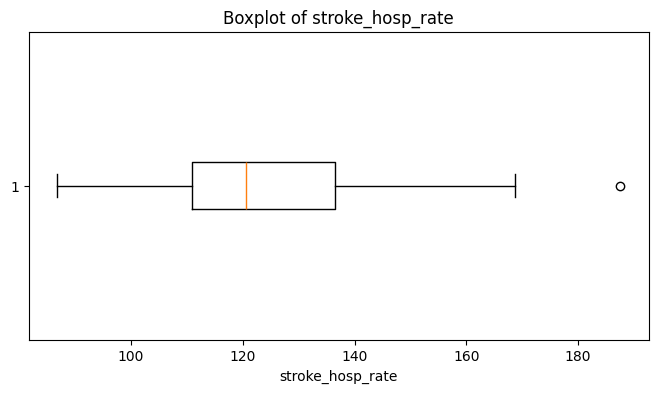

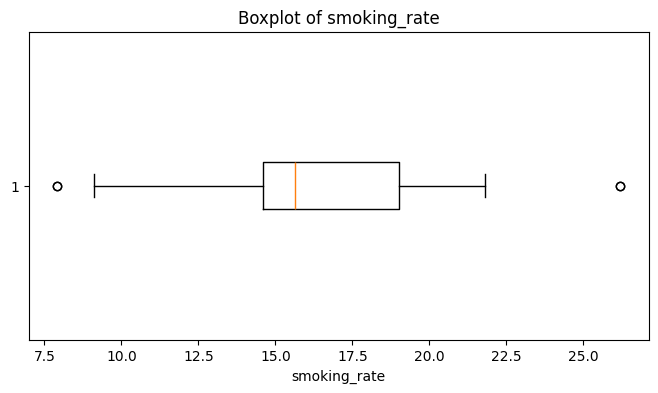

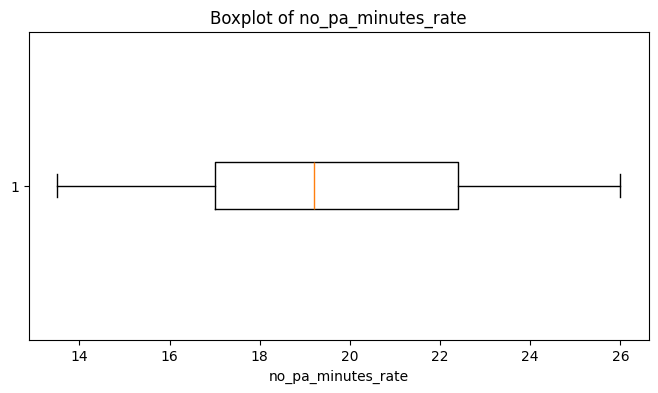

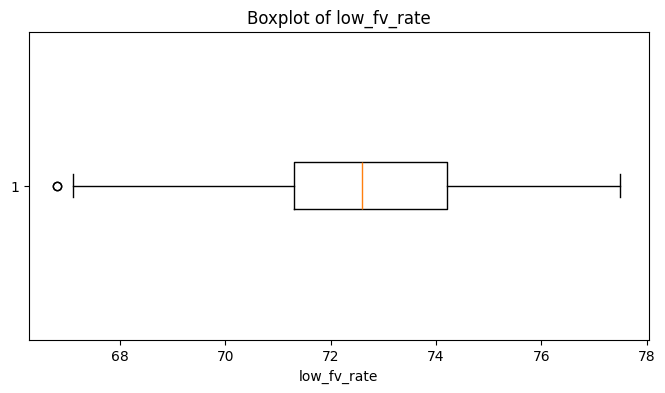

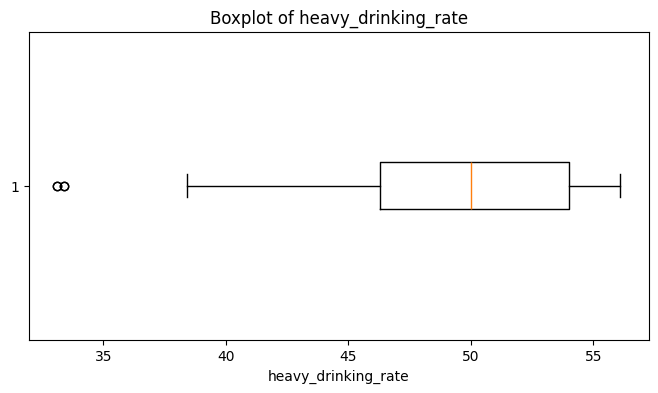

In [21]:
# Step 10. Check for outliers using boxplots

import matplotlib.pyplot as plt

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

In [22]:
# Step 11. Detect potential outliers using IQR

def find_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    
    print("\nColumn:", column)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of outliers:", len(outliers))
    
    if len(outliers) > 0:
        display(outliers[["PHU", "Year", column]])

numeric_cols = [
    "stroke_hosp_rate",
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

for col in numeric_cols:
    find_outliers_iqr(df, col)


Column: stroke_hosp_rate
Lower bound: 72.42499999999998
Upper bound: 174.82500000000002
Number of outliers: 1


,PHU,Year,stroke_hosp_rate
18,Northwestern Health Unit,2016,187.6



Column: smoking_rate
Lower bound: 7.999999999999999
Upper bound: 25.6
Number of outliers: 4


,PHU,Year,smoking_rate
0,Algoma Public Health,2016,26.2
1,Algoma Public Health,2017,26.2
36,York Region Public Health,2016,7.9
37,York Region Public Health,2017,7.9



Column: no_pa_minutes_rate
Lower bound: 8.900000000000002
Upper bound: 30.499999999999996
Number of outliers: 0

Column: low_fv_rate
Lower bound: 66.94999999999999
Upper bound: 78.55000000000001
Number of outliers: 2


,PHU,Year,low_fv_rate
32,Wellington-Dufferin-Guelph Public Health,2016,66.8
33,Wellington-Dufferin-Guelph Public Health,2017,66.8



Column: heavy_drinking_rate
Lower bound: 34.74999999999999
Upper bound: 65.55000000000001
Number of outliers: 4


,PHU,Year,heavy_drinking_rate
22,Peel Public Health,2016,33.1
23,Peel Public Health,2017,33.1
36,York Region Public Health,2016,33.4
37,York Region Public Health,2017,33.4


In [23]:
# Step 12. Verify panel consistency

df[df["PHU"] == df["PHU"].iloc[0]].sort_values("Year")

,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1


In [26]:
# Verify automatically.

risk_cols = [
    "smoking_rate",
    "no_pa_minutes_rate",
    "low_fv_rate",
    "heavy_drinking_rate"
]

for phu in df["PHU"].unique():
    
    temp = df[df["PHU"] == phu].sort_values("Year")
    
    if len(temp) == 2:
        
        same_values = (temp.iloc[0][risk_cols].values == temp.iloc[1][risk_cols].values).all()
        
        if not same_values:
            print("Mismatch found in:", phu)

In [27]:
# Step 13. Sort dataset

df = df.sort_values(["PHU", "Year"]).reset_index(drop=True)

df.head()

,PHU,Year,stroke_hosp_rate,smoking_rate,no_pa_minutes_rate,low_fv_rate,heavy_drinking_rate
0,Algoma Public Health,2016,127.8,26.2,19.0,73.2,55.1
1,Algoma Public Health,2017,131.1,26.2,19.0,73.2,55.1
2,Chatham-Kent Public Health,2016,146.7,19.0,20.6,72.7,49.5
3,Chatham-Kent Public Health,2017,139.0,19.0,20.6,72.7,49.5
4,City of Hamilton Public Health Services,2016,138.5,15.3,17.3,75.3,43.9


In [28]:
# Step 14. Save final cleaned dataset

clean_file = DATA_PROCESSED / "stroke_risk_panel_clean.csv"

df.to_csv(clean_file, index=False)

print("Clean dataset saved at:", clean_file)

Clean dataset saved at: /Users/krishnapatel/Documents/Cohort_Project/data_processed/stroke_risk_panel_clean.csv


In [29]:
# Step 15. Final validation summary

print("Rows:", len(df))
print("PHUs:", df["PHU"].nunique())
print("Years:", sorted(df["Year"].unique()))

Rows: 44
PHUs: 22
Years: [np.int64(2016), np.int64(2017)]
